# XFeat: Group-sum lower bounds + partial Thermometer (2026-10-05)

**새 실험:** 8개/4개 BIN 원소의 합으로 후보를 제거하고, 살아남은 후보만 Thermometer 마스크를 단계적으로 비교합니다. 10월 1일 파일을 수정하지 않은 독립 노트북입니다.

**실행:** Colab에서 `런타임 → 모두 실행`. Drive 연결을 승인하면 기존 `Colab Notebooks/CSE527_datasets`의 COCO/HPatches ZIP을 재사용합니다. 캐시가 없으면 다운로드합니다. CPU 런타임으로 실행 가능하며 GPU는 XFeat 추출에만 사용됩니다. 기본 800 keypoints, synthetic 18쌍 + HPatches 24쌍; 속도는 데이터셋당 5쌍 × 12회입니다.

| 비교 | 목적 |
|---|---|
| float cosine / uint8 ABS / packed Thermometer matrix | 기존 기준선 |
| Thermometer fused, no pruning | pruning 자체 효과를 구분하는 동일 순차 커널 기준선 |
| partial Thermometer | 마스크 계산 조기 종료 |
| group8 / group4 / group8→4 | 묶음 합 하한만 사용 |
| group8 + partial / group8→4 + partial | 두 아이디어 결합 |

**범위:** 이전 제안의 1·2번 구현입니다. Blob, projection/PQ, learned grouping/order는 이 파일에 포함하지 않습니다. 모든 압축 방법은 동일한 고정 BIN-ABS 거리를 사용하므로, 결과가 달라지면 개선이 아니라 구현 오류입니다.

**결과:** precision@3px, correct/mutual 개수, median reprojection error, 양방향 NN/MNN 완전 일치, cached MNN/encoding 포함 시간, pruning·popcount 절약률, bytes/descriptor, 그래프와 CSV/JSON을 출력합니다. XFeat 추출/JIT/검증/I/O는 매칭 시간에서 제외합니다.

학습/평가 원본 이미지 분리를 유지합니다. 수치 비교는 이 노트북 안에서 다시 측정해야 하며 이전 실행의 ms와 직접 결합하지 마세요. 모든 출력은 실행 후 생성되며 과거 결과를 새 결과로 포함하지 않습니다.


## 1. 설정과 기존 데이터 캐시
TOP_K=800은 10월 1일 조건입니다. 필요하면 1000으로 변경하고 전체를 다시 실행하세요. DATA_SOURCE=upload는 여러 장의 원본 사진으로 대체합니다. RUN_HPatches=False는 합성 변환만 평가합니다.

In [1]:
%pip -q install opencv-python-headless numba pandas matplotlib threadpoolctl

import time
import io
import zipfile
import subprocess
import shutil
from pathlib import Path
import cv2
import numpy as np
import torch
import torch.nn.functional as F
from numba import njit, prange, set_num_threads, get_num_threads
from google.colab import files, drive

SEED = 7
TOP_K = 800
LEVELS = 8  # seven thresholds per descriptor dimension
CALIBRATION_WARPS_PER_IMAGE = 6
VALIDATION_WARPS_PER_IMAGE = 3
MAX_POSITIVES_PER_PAIR = 500
GEOMETRIC_THRESHOLD = 3.0
NUMBA_THREADS = 2
RUN_HPatches = True
TIMING_PAIRS_PER_DATASET = 5  # evenly spaced pairs; compare every method on each pair
WARMUP = 3
REPEATS = 12

set_num_threads(NUMBA_THREADS)
torch.set_num_threads(NUMBA_THREADS)
torch.manual_seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

xfeat = torch.hub.load('verlab/accelerated_features', 'XFeat', pretrained=True, top_k=TOP_K, trust_repo=True).to(device).eval()
for parameter in xfeat.parameters():
    parameter.requires_grad_(False)
print('Device:', device)
# COCO is used for calibration and an internal synthetic-warp check.
# No projection or threshold learning. HPatches is reserved for the external real-photo evaluation at the end.
DATA_SOURCE = 'coco'  # change to 'upload' to use your own JPG/PNG files
COCO_SOURCE_COUNT = 24
COCO_URL = 'https://images.cocodataset.org/zips/val2017.zip'
drive.mount('/content/drive')
data_dir = Path('/content/drive/MyDrive/Colab Notebooks/CSE527_datasets')
data_dir.mkdir(parents=True, exist_ok=True)
print('Persistent dataset cache:', data_dir)

def download_archive(url, destination):
    if destination.exists() and zipfile.is_zipfile(destination):
        print('Using persistent Drive cache:', destination)
        return
    # Reuse a download from an earlier run in this same Colab session, if present.
    legacy = Path('/content/xfeat_data') / destination.name
    if legacy.exists() and zipfile.is_zipfile(legacy):
        shutil.copy2(legacy, destination)
        print('Copied previous runtime download into Drive:', destination)
        return
    print('Downloading once into Drive:', url)
    subprocess.run(['wget', '-q', '--show-progress', '-c', '-O', str(destination), url], check=True)
    if not zipfile.is_zipfile(destination):
        raise RuntimeError(f'Incomplete or invalid ZIP: {destination}. Delete it and rerun this cell.')

if DATA_SOURCE == 'coco':
    coco_zip = data_dir / 'val2017.zip'
    download_archive(COCO_URL, coco_zip)
    with zipfile.ZipFile(coco_zip) as archive:
        names = sorted(n for n in archive.namelist() if n.lower().endswith(('.jpg', '.jpeg', '.png')))
        if len(names) < COCO_SOURCE_COUNT:
            raise RuntimeError('COCO archive has fewer images than requested.')
        selected = np.random.default_rng(SEED).choice(len(names), COCO_SOURCE_COUNT, replace=False)
        image_items = [(Path(names[i]).name, archive.read(names[i])) for i in selected]
    print(f'Selected {len(image_items)} COCO images using seed {SEED}; no COCO annotations needed.')
elif DATA_SOURCE == 'upload':
    print('Upload JPG/PNG images from distinct scenes.')
    uploaded = files.upload()
    image_items = list(uploaded.items())
    if not image_items:
        raise ValueError('Upload at least one image.')
else:
    raise ValueError("DATA_SOURCE must be 'coco' or 'upload'")

def decode_and_resize(raw_bytes, maximum_side=640):
    image = cv2.imdecode(np.frombuffer(raw_bytes, np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError('An uploaded file is not a readable JPG/PNG image.')
    height, width = image.shape[:2]
    scale = min(1.0, maximum_side / max(height, width))
    new_width = max(64, (int(width * scale) // 32) * 32)
    new_height = max(64, (int(height * scale) // 32) * 32)
    return cv2.resize(image, (new_width, new_height))

# Split by source image, before any synthetic warps or descriptor calibration.
# Upload images of distinct scenes; near-duplicate photos belong to the same split.
image_items = sorted(image_items)
images = [decode_and_resize(raw) for _, raw in image_items]
if len(images) >= 2:
    split_rng = np.random.default_rng(SEED)
    order = split_rng.permutation(len(images))
    validation_count = max(1, int(np.ceil(0.25 * len(images))))
    validation_ids = set(order[:validation_count].tolist())
    calibration_images = [im for i, im in enumerate(images) if i not in validation_ids]
    validation_images = [im for i, im in enumerate(images) if i in validation_ids]
    print('Calibration files:', [name for i, (name, _) in enumerate(image_items) if i not in validation_ids])
    print('Held-out files:', [name for i, (name, _) in enumerate(image_items) if i in validation_ids])
else:
    raise ValueError('Use at least 2 distinct source images to keep calibration and validation separate.')
print('Calibration images:', len(calibration_images), 'Validation images:', len(validation_images))

Downloading: "https://github.com/verlab/accelerated_features/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://github.com/verlab/accelerated_features/raw/main/weights/xfeat.pt" to /root/.cache/torch/hub/checkpoints/xfeat.pt


100%|██████████| 5.96M/5.96M [00:00<00:00, 295MB/s]


Device: cpu
Mounted at /content/drive
Persistent dataset cache: /content/drive/MyDrive/Colab Notebooks/CSE527_datasets
Using persistent Drive cache: /content/drive/MyDrive/Colab Notebooks/CSE527_datasets/val2017.zip
Selected 24 COCO images using seed 7; no COCO annotations needed.
Calibration files: ['000000002261.jpg', '000000029675.jpg', '000000067534.jpg', '000000162858.jpg', '000000165713.jpg', '000000173008.jpg', '000000175364.jpg', '000000194506.jpg', '000000270402.jpg', '000000289343.jpg', '000000360097.jpg', '000000460841.jpg', '000000471869.jpg', '000000479596.jpg', '000000504711.jpg', '000000517832.jpg', '000000528524.jpg', '000000547383.jpg']
Held-out files: ['000000077595.jpg', '000000132544.jpg', '000000334006.jpg', '000000394559.jpg', '000000449432.jpg', '000000474039.jpg']
Calibration images: 18 Validation images: 6


## 2. 이미지 분리와 XFeat 추출
이전 실험의 이미지 선택 seed, warp, split을 유지합니다. HPatches는 경계 계산에 사용하지 않습니다.

In [2]:
def image_to_tensor(image):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return torch.from_numpy(rgb.copy()).permute(2, 0, 1).float()[None].to(device) / 255.0

@torch.inference_mode()
def extract_features(image):
    output = xfeat.detectAndCompute(image_to_tensor(image), top_k=TOP_K)[0]
    return {
        'keypoints': output['keypoints'].detach().cpu().float(),
        'descriptors': F.normalize(output['descriptors'].detach().cpu().float(), dim=-1),
    }

def make_random_homography(height, width, generator):
    center = (width / 2.0, height / 2.0)
    angle = generator.uniform(-20.0, 20.0)
    scale = generator.uniform(0.88, 1.08)
    affine = cv2.getRotationMatrix2D(center, angle, scale)
    affine[0, 2] += generator.uniform(-0.06, 0.06) * width
    affine[1, 2] += generator.uniform(-0.06, 0.06) * height
    homography = np.vstack([affine, [0., 0., 1.]]).astype(np.float32)
    homography[2, 0] = generator.uniform(-7e-5, 7e-5)
    homography[2, 1] = generator.uniform(-7e-5, 7e-5)
    return homography

def warp_image(image, homography, generator):
    height, width = image.shape[:2]
    warped = cv2.warpPerspective(image, homography, (width, height),
                                 flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    alpha = float(generator.uniform(0.82, 1.12))
    beta = float(generator.uniform(-12., 18.))
    return np.clip(warped.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)

def project_points(points, homography):
    p = points.detach().cpu().numpy()
    p_h = np.concatenate([p, np.ones((len(p), 1), np.float32)], axis=1)
    projected = (homography @ p_h.T).T
    return torch.from_numpy((projected[:, :2] / projected[:, 2:3]).astype(np.float32))

def ground_truth_pairs(keypoints_1, keypoints_2, homography):
    if not len(keypoints_1) or not len(keypoints_2):
        return torch.empty(0, dtype=torch.long), torch.empty(0, dtype=torch.long)
    distances_12 = torch.cdist(project_points(keypoints_1, homography), keypoints_2)
    nearest_12 = distances_12.argmin(dim=1)
    errors = distances_12[torch.arange(len(keypoints_1)), nearest_12]
    distances_21 = torch.cdist(project_points(keypoints_2, np.linalg.inv(homography)), keypoints_1)
    nearest_21 = distances_21.argmin(dim=1)
    indices = torch.arange(len(keypoints_1))
    good = (nearest_21[nearest_12] == indices) & (errors < GEOMETRIC_THRESHOLD)
    return indices[good], nearest_12[good]

def build_pairs(source_images, warps_per_image, generator):
    pairs = []
    for image_index, image in enumerate(source_images):
        base = extract_features(image)
        for warp_index in range(warps_per_image):
            h = make_random_homography(*image.shape[:2], generator)
            warped = extract_features(warp_image(image, h, generator))
            i, j = ground_truth_pairs(base['keypoints'], warped['keypoints'], h)
            if len(i) > MAX_POSITIVES_PER_PAIR:
                keep = torch.randperm(len(i))[:MAX_POSITIVES_PER_PAIR]
                i, j = i[keep], j[keep]
            if len(i) < 32:
                print(f'Warning: image {image_index}, warp {warp_index}: {len(i)} positive pairs')
            pairs.append({'d1': base['descriptors'], 'd2': warped['descriptors'],
                          'k1': base['keypoints'], 'k2': warped['keypoints'],
                          'pos1': i, 'pos2': j, 'H': h})
    return pairs

start = time.perf_counter()
calibration_pairs = build_pairs(calibration_images, CALIBRATION_WARPS_PER_IMAGE, rng)
validation_pairs = build_pairs(validation_images, VALIDATION_WARPS_PER_IMAGE, rng)
calibration = torch.cat([torch.cat([p['d1'], p['d2']], dim=0) for p in calibration_pairs], dim=0)
if len(calibration) > 50000:
    calibration = calibration[torch.randperm(len(calibration))[:50000]]
print('Feature extraction time (calibration and validation):', round(time.perf_counter() - start, 2), 's')
print('Calibration pairs:', len(calibration_pairs), 'Validation pairs:', len(validation_pairs),
      'Calibration descriptors:', len(calibration))

Feature extraction time (calibration and validation): 49.84 s
Calibration pairs: 108 Validation pairs: 18 Calibration descriptors: 50000


In [3]:
# Fixed training-partition quantile edges; no optimizer, projection, or threshold learning.
base_edges_cpu = torch.quantile(calibration, torch.arange(1, LEVELS).float() / LEVELS, dim=0).T.contiguous()

def hard_quantize(descriptors, edges):
    return (descriptors[:, :, None] > edges[None, :, :]).sum(dim=-1).to(torch.uint8)

print('Fixed edges:', tuple(base_edges_cpu.shape), '| learned parameters: 0')


Fixed edges: (64, 7) | learned parameters: 0


## 3. 기존 거리 커널과 검증
BIN 거리 최대값은 448입니다. uint16 거리, uint64 Thermometer 7개를 사용합니다.

In [4]:
@njit(parallel=True, cache=False)
def pairwise_uint8_abs(code_1, code_2):
    out = np.empty((code_1.shape[0], code_2.shape[0]), np.uint16)
    for i in prange(code_1.shape[0]):
        for j in range(code_2.shape[0]):
            total = 0
            for k in range(code_1.shape[1]):
                a, b = int(code_1[i, k]), int(code_2[j, k])
                total += a - b if a >= b else b - a
            out[i, j] = total
    return out

def mutual_from_scores(scores, higher_is_better):
    if not scores.shape[0] or not scores.shape[1]:
        return np.empty(0, dtype=np.int64), np.empty(0, dtype=np.int64)
    if higher_is_better:
        nearest_12, nearest_21 = scores.argmax(axis=1), scores.argmax(axis=0)
    else:
        nearest_12, nearest_21 = scores.argmin(axis=1), scores.argmin(axis=0)
    indices = np.arange(scores.shape[0])
    keep = nearest_21[nearest_12] == indices
    return indices[keep], nearest_12[keep]

def encode(desc, edges):
    with torch.no_grad():
        levels = hard_quantize(desc.to(device), edges.to(device))
    return np.ascontiguousarray(levels.cpu().numpy(), dtype=np.uint8)

def match_float(pair):
    scores = (pair['d1'] @ pair['d2'].T).numpy()
    return mutual_from_scores(scores, higher_is_better=True)

def match_abs(pair, edges):
    a, b = encode(pair['d1'], edges), encode(pair['d2'], edges)
    return mutual_from_scores(pairwise_uint8_abs(a, b), higher_is_better=False)


# Packed thermometer: same 8-bin L1 distance, different computation.
from numba import types
from numba.extending import intrinsic
from llvmlite import ir

@intrinsic
def thermometer_popcount64(typing_context, value_type):
    if value_type != types.uint64:
        raise TypeError('thermometer_popcount64 expects uint64')
    signature = types.uint64(types.uint64)
    def codegen(context, builder, signature, arguments):
        function = builder.module.declare_intrinsic('llvm.ctpop', [ir.IntType(64)])
        return builder.call(function, arguments)
    return signature, codegen

@njit(cache=False)
def _pack_thermometer64(codes):
    packed = np.zeros((codes.shape[0], 7), dtype=np.uint64)
    for row in range(codes.shape[0]):
        for threshold in range(1, 8):
            word = np.uint64(0)
            for dimension in range(64):
                if codes[row, dimension] >= threshold:
                    word |= np.uint64(1) << np.uint64(dimension)
            packed[row, threshold - 1] = word
    return packed

def pack_thermometer64(codes):
    codes = np.asarray(codes)
    if codes.ndim != 2 or codes.shape[1] != 64:
        raise ValueError('Expected (N, 64) bin indices')
    if not np.issubdtype(codes.dtype, np.integer):
        raise ValueError('Bin indices must be integers')
    if codes.size and (codes.min() < 0 or codes.max() > 7):
        raise ValueError('Expected bin indices 0..7')
    return _pack_thermometer64(np.ascontiguousarray(codes, dtype=np.uint8))

@njit(parallel=True, cache=False)
def pairwise_thermometer64(packed_1, packed_2):
    distances = np.empty((packed_1.shape[0], packed_2.shape[0]), dtype=np.uint16)
    for i in prange(packed_1.shape[0]):
        for j in range(packed_2.shape[0]):
            total = np.uint64(0)
            for plane in range(7):
                total += thermometer_popcount64(packed_1[i, plane] ^ packed_2[j, plane])
            distances[i, j] = total
    return distances

def match_thermometer(pair, edges):
    a = pack_thermometer64(encode(pair['d1'], edges))
    b = pack_thermometer64(encode(pair['d2'], edges))
    return mutual_from_scores(pairwise_thermometer64(a, b), higher_is_better=False)

def verify_thermometer_codes(a, b):
    abs_distances = pairwise_uint8_abs(a, b)
    thermo_distances = pairwise_thermometer64(pack_thermometer64(a), pack_thermometer64(b))
    np.testing.assert_array_equal(abs_distances, thermo_distances)
    if len(a) and len(b):
        abs_matches = mutual_from_scores(abs_distances, False)
        thermo_matches = mutual_from_scores(thermo_distances, False)
        for abs_indices, thermo_indices in zip(abs_matches, thermo_matches):
            np.testing.assert_array_equal(abs_indices, thermo_indices)
    return True

if LEVELS != 8:
    raise ValueError('This experiment is for 8 bins and 64 dimensions')
# Compile before measurements; test all 8x8 scalar values at bits 0 and 63.
for dimension in (0, 63):
    scalar_codes = np.zeros((8, 64), dtype=np.uint8)
    scalar_codes[:, dimension] = np.arange(8, dtype=np.uint8)
    verify_thermometer_codes(scalar_codes, scalar_codes)
    expected = np.abs(np.arange(8)[:, None] - np.arange(8)[None, :])
    np.testing.assert_array_equal(pairwise_thermometer64(
        pack_thermometer64(scalar_codes), pack_thermometer64(scalar_codes)), expected)
test_rng = np.random.default_rng(SEED)
verify_thermometer_codes(test_rng.integers(0, 8, (19, 64), dtype=np.uint8),
                         test_rng.integers(0, 8, (23, 64), dtype=np.uint8))
zeros = np.zeros((1, 64), dtype=np.uint8)
sevens = np.full((1, 64), 7, dtype=np.uint8)
verify_thermometer_codes(zeros, sevens)
assert int(pairwise_thermometer64(pack_thermometer64(zeros), pack_thermometer64(sevens))[0, 0]) == 448
assert pack_thermometer64(zeros).nbytes == 56
print('PASS: scalar cases, highest bit, random distances/MNN, maximum distance 448.')
print('Storage per descriptor: float32 256 B | uint8 ABS 64 B | packed thermometer 56 B.')
print('Thermometer is 7 threshold planes, not the 24 B packed 3-bit numeric representation.')


PASS: scalar cases, highest bit, random distances/MNN, maximum distance 448.
Storage per descriptor: float32 256 B | uint8 ABS 64 B | packed thermometer 56 B.
Thermometer is 7 threshold planes, not the 24 B packed 3-bit numeric representation.


## 4. 새 pruning 커널과 정확성 검사

그룹 하한: `sum_g |sum(a_group)-sum(b_group)| <= sum_d |a_d-b_d|`.
8개 그룹을 4개씩으로 나눌수록 하한이 커지거나 같습니다. **마스크 부분합과 그룹 하한을 서로 더하지 않습니다** — 같은 거리에 대한 하한들이므로 더하면 안전하지 않습니다.

쌍을 제거하는 조건은 `lower > max(best_row, best_column)`입니다. 동점은 제거하지 않고 가장 작은 인덱스를 유지합니다. 모든 순차 방법은 동일한 i→j 순서이며, 학습된 순서/후보 선별을 사용하지 않습니다. Pruning 비용이 절약보다 크면 더 느려질 수 있습니다.

검사: 무작위 크기, 중복·동점, 빈 집합, 0/7 극값, bit63, 두 방향 NN, MNN 기준의 부모 NN, 하한 부등식, 통계 합계. 실제 평가 쌍도 모두 다시 검사합니다.


In [5]:
# Exact serial fused baseline and pruning ablations. No shared-array races.
@njit(cache=False)
def group_sums(q, width):
    out = np.zeros((len(q), 64 // width), np.uint8)
    for i in range(len(q)):
        for g in range(64 // width):
            s = 0
            for k in range(width):
                s += int(q[i, g * width + k])
            out[i, g] = s
    return out

@njit(cache=False)
def exact_pruned_nearest(pa, pb, a8, b8, a4, b4, order,
                         use8, use4, partial, stats=False):
    n, m = len(pa), len(pb)
    row_d = np.full(n, 449, np.int64)
    col_d = np.full(m, 449, np.int64)
    row_j = np.full(n, -1, np.int64)
    col_i = np.full(m, -1, np.int64)
    # pairs, rejected8, rejected4, rejected_partial, full, popcounts, group_terms
    counts = np.zeros(7, np.int64)
    for i in range(n):
        for j in range(m):
            if stats: counts[0] += 1
            # To omit a pair from BOTH directional searches it must lose BOTH.
            cutoff = max(row_d[i], col_d[j])
            if use8:
                lower = 0
                for g in range(8):
                    lower += abs(np.int64(a8[i,g]) - np.int64(b8[j,g]))
                if stats: counts[6] += 8
                if lower > cutoff:
                    if stats: counts[1] += 1
                    continue
            if use4:
                lower = 0
                for g in range(16):
                    lower += abs(np.int64(a4[i,g]) - np.int64(b4[j,g]))
                if stats: counts[6] += 16
                if lower > cutoff:
                    if stats: counts[2] += 1
                    continue
            total = 0
            rejected = False
            for t in range(7):
                k = order[t]
                total += np.int64(thermometer_popcount64(pa[i,k] ^ pb[j,k]))
                if stats: counts[5] += 1
                # Do not label completing all seven planes as an early exit.
                if partial and t < 6 and total > cutoff:
                    rejected = True
                    if stats: counts[3] += 1
                    break
            if rejected: continue
            if stats: counts[4] += 1
            # Traversal is ascending: strict improvement preserves first-index ties.
            if total < row_d[i]:
                row_d[i], row_j[i] = total, j
            if total < col_d[j]:
                col_d[j], col_i[j] = total, i
    return row_j, col_i, counts

def mutual_from_nearest(n12, n21):
    if not len(n12) or not len(n21):
        return np.empty(0, np.int64), np.empty(0, np.int64)
    i = np.arange(len(n12))
    valid = n12 >= 0
    i = i[valid]
    i = i[n21[n12[i]] == i]
    return i, n12[i]

# All these retain the exact original fixed-bin ABS metric.
VARIANTS = {
    'thermo_fused_no_prune': (False, False, False),
    'thermo_partial': (False, False, True),
    'group8_only': (True, False, False),
    'group4_only': (False, True, False),
    'group8_then4': (True, True, False),
    'group8_partial': (True, False, True),
    'group8_then4_partial': (True, True, True),
}
NATURAL_ORDER = np.arange(7, dtype=np.int64)
EMPTY_GROUP = np.empty((0, 0), np.uint8)

def prepare_codes(a, b):
    return dict(a=a, b=b, pa=pack_thermometer64(a), pb=pack_thermometer64(b),
                a8=group_sums(a,8), b8=group_sums(b,8),
                a4=group_sums(a,4), b4=group_sums(b,4))

def run_variant(p, name, stats=False):
    flags = VARIANTS[name]
    return exact_pruned_nearest(p['pa'], p['pb'], p['a8'], p['b8'],
                                p['a4'], p['b4'], NATURAL_ORDER, *flags, stats)

def check_codes(a, b):
    p = prepare_codes(a,b)
    d = pairwise_uint8_abs(a,b)
    np.testing.assert_array_equal(d, pairwise_thermometer64(p['pa'],p['pb']))
    if len(a) and len(b):
        expected = d.argmin(1), d.argmin(0)
        l8 = np.abs(p['a8'].astype(np.int16)[:,None,:] - p['b8'].astype(np.int16)[None,:,:]).sum(2)
        l4 = np.abs(p['a4'].astype(np.int16)[:,None,:] - p['b4'].astype(np.int16)[None,:,:]).sum(2)
        assert np.all(l8 <= l4) and np.all(l4 <= d)
    else:
        expected = np.full(len(a),-1), np.full(len(b),-1)
    for name in VARIANTS:
        r,c,s = run_variant(p,name,True)
        np.testing.assert_array_equal(r,expected[0],err_msg=name)
        np.testing.assert_array_equal(c,expected[1],err_msg=name)
        assert s[0] == len(a)*len(b)
        assert s[1:5].sum() == s[0]
        assert s[5] <= 7*s[0]
        r2,c2,_ = run_variant(p,name,False)
        np.testing.assert_array_equal(r,r2)
        np.testing.assert_array_equal(c,c2)


def test_pruning():
    r = np.random.default_rng(7)
    for n,m in [(0,0),(0,4),(4,0),(1,1),(1,23),(19,1),(19,23),(80,75)]:
        check_codes(r.integers(0,8,(n,64),dtype=np.uint8),r.integers(0,8,(m,64),dtype=np.uint8))
    check_codes(np.zeros((9,64),np.uint8),np.zeros((12,64),np.uint8))
    check_codes(np.zeros((3,64),np.uint8),np.full((5,64),7,np.uint8))
    q=r.integers(0,8,(25,64),dtype=np.uint8)
    check_codes(np.repeat(q,2,axis=0),np.repeat(q[::-1],3,axis=0))
    # Exhaust all 8 levels at both the least and most significant packed bits.
    for k in (0,63):
        q=np.zeros((8,64),np.uint8); q[:,k]=np.arange(8)
        check_codes(q,q[::-1].copy())
    print('PASS: exact distances, 8→4 lower bounds, both NN directions, ties, duplicates, empty sets, maximum distance and statistics.')

test_pruning()


PASS: exact distances, 8→4 lower bounds, both NN directions, ties, duplicates, empty sets, maximum distance and statistics.


## 5. HPatches 실제 이미지 평가 쌍
기존과 동일한 6 viewpoint + 6 illumination 시퀀스의 1→2, 1→3을 사용합니다. resize 변환을 H에 적용합니다.

In [6]:
real_pairs = []
if RUN_HPatches:
    HPATCHES_URL = 'https://huggingface.co/datasets/vbalnt/hpatches/resolve/main/hpatches-sequences-release.zip'
    HPATCHES_SEQUENCES_PER_TYPE = 6  # 6 viewpoint + 6 illumination scenes
    HPATCHES_TARGETS = (2, 3)       # two real photos per sequence
    hpatches_zip = data_dir / 'hpatches-sequences-release.zip'
    download_archive(HPATCHES_URL, hpatches_zip)

    def decode_hpatches_with_scale(raw_bytes):
        original = cv2.imdecode(np.frombuffer(raw_bytes, np.uint8), cv2.IMREAD_COLOR)
        if original is None:
            raise RuntimeError('Failed to decode HPatches PPM image')
        old_h, old_w = original.shape[:2]
        resized = decode_and_resize(raw_bytes)
        new_h, new_w = resized.shape[:2]
        scale = np.diag([new_w / old_w, new_h / old_h, 1.0]).astype(np.float64)
        return resized, scale

    real_pairs = []
    with zipfile.ZipFile(hpatches_zip) as archive:
        entries = set(archive.namelist())
        folders = sorted({name.rsplit('/', 1)[0] for name in entries if name.endswith('/1.ppm')})
        for prefix in ('v_', 'i_'):
            selected_folders = [folder for folder in folders if folder.split('/')[-1].startswith(prefix)]
            if len(selected_folders) < HPATCHES_SEQUENCES_PER_TYPE:
                raise RuntimeError(f'Expected more HPatches {prefix} folders; found {len(selected_folders)}')
            for folder in selected_folders[:HPATCHES_SEQUENCES_PER_TYPE]:
                image_1, scale_1 = decode_hpatches_with_scale(archive.read(folder + '/1.ppm'))
                features_1 = extract_features(image_1)
                for target_id in HPATCHES_TARGETS:
                    image_name = f'{folder}/{target_id}.ppm'
                    h_name = f'{folder}/H_1_{target_id}'
                    if image_name not in entries or h_name not in entries:
                        raise RuntimeError(f'Missing HPatches image or homography: {folder}, {target_id}')
                    image_2, scale_2 = decode_hpatches_with_scale(archive.read(image_name))
                    features_2 = extract_features(image_2)
                    original_h = np.loadtxt(io.BytesIO(archive.read(h_name))).reshape(3, 3)
                    resized_h = scale_2 @ original_h @ np.linalg.inv(scale_1)
                    real_pairs.append({
                        'name': f'{folder.split("/")[-1]}:1->{target_id}',
                        'group': prefix, 'd1': features_1['descriptors'],
                        'd2': features_2['descriptors'],
                        'k1': features_1['keypoints'], 'k2': features_2['keypoints'],
                        'H': resized_h,
                    })
    print('HPatches real-photo pairs:', len(real_pairs), '(viewpoint and illumination)')



Using persistent Drive cache: /content/drive/MyDrive/Colab Notebooks/CSE527_datasets/hpatches-sequences-release.zip
HPatches real-photo pairs: 24 (viewpoint and illumination)


## 6. 정확도·속도 비교와 그래프

- CPU 매칭과 CPU 양자화로 장치 전송을 타이밍에서 배제합니다.
- ABS/Thermometer matrix는 설정한 2 threads, 새 fused 커널은 1 thread입니다. `fused_no_prune` 대비 속도가 pruning 효과를 보여줍니다.
- 인코딩 비용은 해당 방법에 필요한 표현만 만듭니다. float 입력은 XFeat에서 정규화된 float32입니다.
- JIT warmup 후 반복마다 방법/측정 단계 순서를 섞습니다. 통계 수집은 타이밍 밖에서 수행합니다.
- 저장량: thermometer 56B, +group8=64B, +group4=72B, +둘 다=80B입니다. 압축률 개선이 아니라 보조 요약에 의한 가속 실험입니다. 작업 메모리와 코드/경계 저장량은 별도입니다.
- 정확한 방법의 precision이 동일한 것은 정상입니다. 속도·제거율에서 차이를 확인하세요.


Payload bytes per descriptor (working allocations excluded): {'float_cosine': 256, 'uint8_ABS': 64, 'thermo_matrix': 56, 'thermo_fused_no_prune': 56, 'thermo_partial': 56, 'group8_only': 64, 'group4_only': 72, 'group8_then4': 80, 'group8_partial': 64, 'group8_then4_partial': 80}
Verified: synthetic 0 800 x 800
Verified: synthetic 1 800 x 800
Verified: synthetic 2 800 x 800
Verified: synthetic 3 800 x 800
Verified: synthetic 4 800 x 800
Verified: synthetic 5 800 x 800
Verified: synthetic 6 800 x 800
Verified: synthetic 7 800 x 800
Verified: synthetic 8 800 x 800
Verified: synthetic 9 800 x 800
Verified: synthetic 10 800 x 800
Verified: synthetic 11 800 x 800
Verified: synthetic 12 800 x 800
Verified: synthetic 13 800 x 800
Verified: synthetic 14 800 x 800
Verified: synthetic 15 800 x 800
Verified: synthetic 16 800 x 800
Verified: synthetic 17 800 x 800
Verified: HPatches v_abstract:1->2 800 x 800
Verified: HPatches v_abstract:1->3 800 x 800
Verified: HPatches v_adam:1->2 800 x 800
Verif

,dataset,method,mutual,correct,precision_pct,median_px,exact_abs_mnn,bytes_per_descriptor
0,synthetic,float_cosine,8178,5598,68.4519,1.3656,False,256
1,synthetic,uint8_ABS,8069,5404,66.9724,1.4109,True,64
2,synthetic,thermo_matrix,8069,5404,66.9724,1.4109,True,56
3,synthetic,thermo_fused_no_prune,8069,5404,66.9724,1.4109,True,56
4,synthetic,thermo_partial,8069,5404,66.9724,1.4109,True,56
5,synthetic,group8_only,8069,5404,66.9724,1.4109,True,64
6,synthetic,group4_only,8069,5404,66.9724,1.4109,True,72
7,synthetic,group8_then4,8069,5404,66.9724,1.4109,True,80
8,synthetic,group8_partial,8069,5404,66.9724,1.4109,True,64
9,synthetic,group8_then4_partial,8069,5404,66.9724,1.4109,True,80


Precision is pooled correct/mutual. Median uses all matched errors, not only correct matches.
3px is in resized image coordinates. This is a matching experiment, not the official HPatches descriptor benchmark.
Timed: synthetic 0
Timed: synthetic 4
Timed: synthetic 8
Timed: synthetic 12
Timed: synthetic 17
Timed: HPatches 0
Timed: HPatches 5
Timed: HPatches 11
Timed: HPatches 17
Timed: HPatches 23


,dataset,method,mutual,correct,precision_pct,median_px,exact_abs_mnn,bytes_per_descriptor,cached_mnn_ms,encode_mnn_ms,encode_only_ms,speedup_vs_thermo_cached,speedup_vs_float_cached,speedup_vs_fused_cached
0,synthetic,float_cosine,8178,5598,68.4519,1.3656,False,256,3.4908,3.6387,0.0000,1.1290,1.0000,5.8532
1,synthetic,uint8_ABS,8069,5404,66.9724,1.4109,True,64,8.4988,13.7478,5.8566,0.4637,0.4107,2.4042
2,synthetic,thermo_matrix,8069,5404,66.9724,1.4109,True,56,3.9412,9.2063,5.2656,1.0000,0.8857,5.1843
3,synthetic,thermo_fused_no_prune,8069,5404,66.9724,1.4109,True,56,20.4325,28.9680,6.4238,0.1929,0.1708,1.0000
4,synthetic,thermo_partial,8069,5404,66.9724,1.4109,True,56,18.7446,24.3907,5.4212,0.2103,0.1862,1.0900
5,synthetic,group8_only,8069,5404,66.9724,1.4109,True,64,16.5262,27.7629,6.7455,0.2385,0.2112,1.2364
6,synthetic,group4_only,8069,5404,66.9724,1.4109,True,72,18.1920,23.1156,5.5181,0.2166,0.1919,1.1232
7,synthetic,group8_then4,8069,5404,66.9724,1.4109,True,80,22.4481,27.4188,5.7394,0.1756,0.1555,0.9102
8,synthetic,group8_partial,8069,5404,66.9724,1.4109,True,64,18.1684,24.5313,5.7662,0.2169,0.1921,1.1246
9,synthetic,group8_then4_partial,8069,5404,66.9724,1.4109,True,80,28.3795,42.0582,6.9570,0.1389,0.1230,0.7200


,dataset,method,popcount_saved_pct
0,HPatches,group4_only,26.57
1,HPatches,group8_only,8.97
2,HPatches,group8_partial,38.75
3,HPatches,group8_then4,26.57
4,HPatches,group8_then4_partial,48.38
5,HPatches,thermo_fused_no_prune,0.00
6,HPatches,thermo_partial,34.73
7,synthetic,group4_only,31.30
8,synthetic,group8_only,9.96
9,synthetic,group8_partial,40.34


Speedup >1 means faster. Timings: median of per-pair medians; repeat samples saved separately.
Matrix baselines use 2 threads; fused/pruned kernels are serial. Compare against fused_no_prune to isolate pruning.
Group summaries add storage: 56B thermometer + 8B group8 + optional 16B group4.


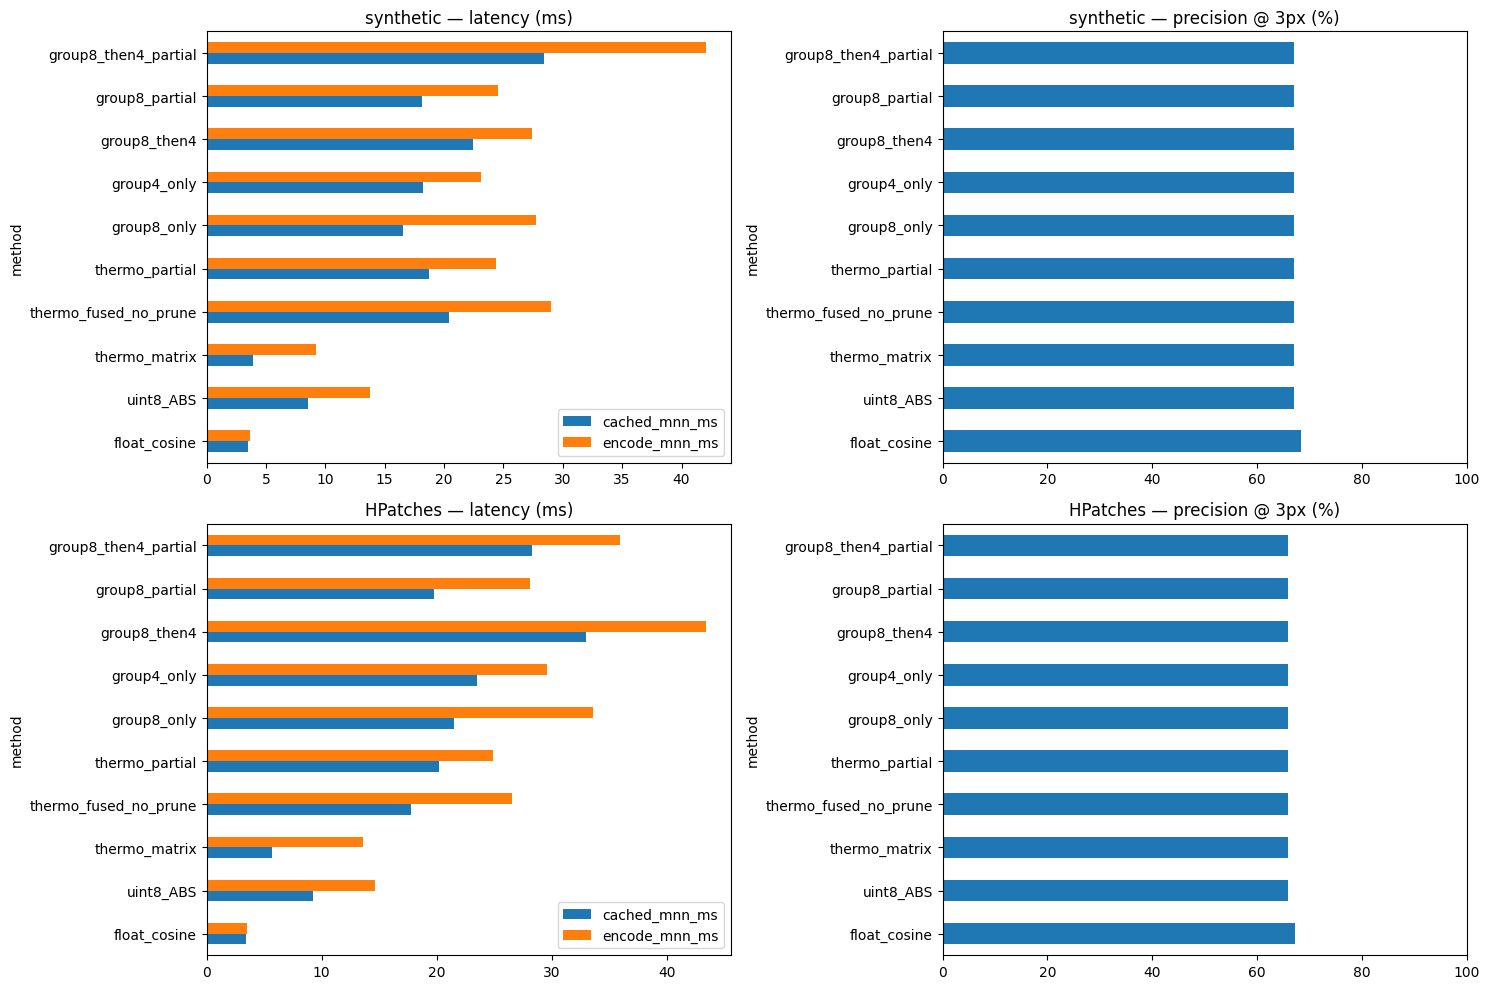

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import platform, json, sys, hashlib
from datetime import datetime
from zoneinfo import ZoneInfo

# CPU quantization for every method: no GPU transfers hidden inside timers.
EDGES = np.ascontiguousarray(base_edges_cpu.numpy(), dtype=np.float32)
def quantize_cpu(x):
    return np.ascontiguousarray((x[:,:,None] > EDGES[None,:,:]).sum(2), dtype=np.uint8)

def prepare_pair(pair):
    p = {**pair}
    p['x'] = np.ascontiguousarray(pair['d1'].numpy(),dtype=np.float32)
    p['y'] = np.ascontiguousarray(pair['d2'].numpy(),dtype=np.float32)
    p.update(prepare_codes(quantize_cpu(p['x']),quantize_cpu(p['y'])))
    return p

METHODS = ['float_cosine','uint8_ABS','thermo_matrix'] + list(VARIANTS)

def match_prepared(p, name):
    if name == 'float_cosine':
        return mutual_from_scores(p['x'] @ p['y'].T,True)
    if name == 'uint8_ABS':
        return mutual_from_scores(pairwise_uint8_abs(p['a'],p['b']),False)
    if name == 'thermo_matrix':
        return mutual_from_scores(pairwise_thermometer64(p['pa'],p['pb']),False)
    r,c,_ = run_variant(p,name)
    return mutual_from_nearest(r,c)

def encode_for_method(p,name):
    # Construct only the representations required by this method.
    z = {'x':p['x'],'y':p['y']}
    if name == 'float_cosine': return z
    a,b=quantize_cpu(p['x']),quantize_cpu(p['y'])
    if name == 'uint8_ABS': return dict(a=a,b=b)
    z={'pa':pack_thermometer64(a),'pb':pack_thermometer64(b)}
    if name == 'thermo_matrix': return z
    use8,use4,_=VARIANTS[name]
    z.update(a8=group_sums(a,8) if use8 else EMPTY_GROUP,
             b8=group_sums(b,8) if use8 else EMPTY_GROUP,
             a4=group_sums(a,4) if use4 else EMPTY_GROUP,
             b4=group_sums(b,4) if use4 else EMPTY_GROUP)
    return z

def match_inclusive(p,name):
    return match_prepared(encode_for_method(p,name),name)

BYTES={'float_cosine':256,'uint8_ABS':64,'thermo_matrix':56}
BYTES.update({name:56+8*flags[0]+16*flags[1] for name,flags in VARIANTS.items()})
print('Payload bytes per descriptor (working allocations excluded):',BYTES)

prepared_datasets={'synthetic':[prepare_pair(p) for p in validation_pairs]}
if real_pairs: prepared_datasets['HPatches']=[prepare_pair(p) for p in real_pairs]
accuracy_rows=[]; pruning_rows=[]; error_cache={}
for dataset,pairs in prepared_datasets.items():
    for pi,p in enumerate(pairs):
        ref=pairwise_uint8_abs(p['a'],p['b'])
        np.testing.assert_array_equal(ref,pairwise_thermometer64(p['pa'],p['pb']))
        baseline=mutual_from_scores(ref,False)
        n,m=len(p['a']),len(p['b'])
        name_pair=p.get('name',str(pi))
        for name in METHODS:
            match=match_prepared(p,name)
            if name!='float_cosine':
                for x,y in zip(baseline,match): np.testing.assert_array_equal(x,y,err_msg=name)
            if name in VARIANTS:
                r,c,s=run_variant(p,name,True)
                if n and m:
                    np.testing.assert_array_equal(r,ref.argmin(1))
                    np.testing.assert_array_equal(c,ref.argmin(0))
                pruning_rows.append(dict(dataset=dataset,pair=pi,method=name,
                    total_pairs=int(s[0]),rejected_group8=int(s[1]),rejected_group4=int(s[2]),
                    rejected_partial=int(s[3]),full_distances=int(s[4]),
                    popcounts=int(s[5]),group_terms=int(s[6]),
                    popcount_saved_pct=100*(1-s[5]/(7*n*m)) if n*m else 0))
            i,j=match
            errors=np.linalg.norm(project_points(p['k1'][i],p['H']).numpy()-p['k2'][j].numpy(),axis=1)
            error_cache.setdefault((dataset,name),[]).extend(errors.tolist())
            correct=int((errors<GEOMETRIC_THRESHOLD).sum())
            accuracy_rows.append(dict(dataset=dataset,pair=pi,pair_name=name_pair,
                group=p.get('group','synthetic'),method=name,n=n,m=m,mutual=len(i),correct=correct,
                precision_pct=100*correct/len(i) if len(i) else np.nan,
                median_px=float(np.median(errors)) if len(i) else np.nan,
                exact_abs_mnn=(name!='float_cosine')))
        print('Verified:',dataset,name_pair,n,'x',m)
accuracy=pd.DataFrame(accuracy_rows)
pruning=pd.DataFrame(pruning_rows)
summary_rows=[]
for (dataset,name),g in accuracy.groupby(['dataset','method'],sort=False):
    mutual=int(g.mutual.sum()); correct=int(g.correct.sum()); errors=error_cache[dataset,name]
    summary_rows.append(dict(dataset=dataset,method=name,mutual=mutual,correct=correct,
        precision_pct=100*correct/mutual if mutual else np.nan,
        median_px=np.median(errors) if errors else np.nan,
        exact_abs_mnn=name!='float_cosine',bytes_per_descriptor=BYTES[name]))
summary=pd.DataFrame(summary_rows)
display(summary.round(4))
print('Precision is pooled correct/mutual. Median uses all matched errors, not only correct matches.')
print('3px is in resized image coordinates. This is a matching experiment, not the official HPatches descriptor benchmark.')

# Paired timing: all methods use exactly the same selected pairs.
# Randomize method order in each repeat; exclude JIT, extraction, stats, verification, disk I/O.
from threadpoolctl import threadpool_limits, threadpool_info

def timed(fn):
    t=time.perf_counter_ns(); fn(); return (time.perf_counter_ns()-t)/1e6

timing_samples=[]
with threadpool_limits(limits=NUMBA_THREADS):
    for dataset,pairs in prepared_datasets.items():
        ids=np.unique(np.linspace(0,len(pairs)-1,min(TIMING_PAIRS_PER_DATASET,len(pairs)),dtype=int))
        for pi in ids:
            p=pairs[pi]
            if not len(p['x']) or not len(p['y']):
                print('Timing skipped empty pair:',dataset,pi); continue
            # Check the inclusive path too (different minimal dictionaries).
            for name in METHODS:
                got=match_inclusive(p,name); want=match_prepared(p,name)
                for a,b in zip(got,want): np.testing.assert_array_equal(a,b)
                for _ in range(WARMUP):
                    match_prepared(p,name); match_inclusive(p,name); encode_for_method(p,name)
            trng=np.random.default_rng(SEED+int(pi))
            for repeat in range(REPEATS):
                for name in trng.permutation(METHODS):
                    timings={}
                    phases=['cached_mnn_ms','encode_mnn_ms','encode_only_ms']
                    for phase in trng.permutation(phases):
                        if phase=='cached_mnn_ms': fn=lambda:match_prepared(p,name)
                        elif phase=='encode_mnn_ms': fn=lambda:match_inclusive(p,name)
                        else: fn=lambda:encode_for_method(p,name)
                        timings[phase]=timed(fn) if name!='float_cosine' or phase!='encode_only_ms' else 0.
                    timing_samples.append(dict(dataset=dataset,pair=int(pi),method=str(name),repeat=repeat,
                        n=len(p['x']),m=len(p['y']),**timings))
            print('Timed:',dataset,pi)
    blas_metadata=threadpool_info()
timing_raw=pd.DataFrame(timing_samples)
time_cols=['cached_mnn_ms','encode_mnn_ms','encode_only_ms']
per_pair=timing_raw.groupby(['dataset','pair','method'])[time_cols].median().reset_index()
timing_summary=per_pair.groupby(['dataset','method'])[time_cols].median().reset_index()
for dataset,g in timing_summary.groupby('dataset'):
    ref=g.set_index('method')
    mask=timing_summary.dataset==dataset
    timing_summary.loc[mask,'speedup_vs_thermo_cached']=float(ref.loc['thermo_matrix','cached_mnn_ms'])/timing_summary.loc[mask,'cached_mnn_ms']
    timing_summary.loc[mask,'speedup_vs_float_cached']=float(ref.loc['float_cosine','cached_mnn_ms'])/timing_summary.loc[mask,'cached_mnn_ms']
    timing_summary.loc[mask,'speedup_vs_fused_cached']=float(ref.loc['thermo_fused_no_prune','cached_mnn_ms'])/timing_summary.loc[mask,'cached_mnn_ms']
comparison=summary.merge(timing_summary,on=['dataset','method'],how='left')
display(comparison.round(4))
display(pruning.groupby(['dataset','method']).popcount_saved_pct.mean().reset_index().round(2))
print('Speedup >1 means faster. Timings: median of per-pair medians; repeat samples saved separately.')
print('Matrix baselines use',NUMBA_THREADS,'threads; fused/pruned kernels are serial. Compare against fused_no_prune to isolate pruning.')
print('Group summaries add storage: 56B thermometer + 8B group8 + optional 16B group4.')

fig,axes=plt.subplots(len(prepared_datasets),2,figsize=(15,5*len(prepared_datasets)),squeeze=False)
for row,dataset in enumerate(prepared_datasets):
    g=comparison[comparison.dataset==dataset].set_index('method').reindex(METHODS)
    g[['cached_mnn_ms','encode_mnn_ms']].plot.barh(ax=axes[row,0],title=dataset+' — latency (ms)')
    g[['precision_pct']].plot.barh(ax=axes[row,1],title=dataset+' — precision @ 3px (%)',legend=False)
    axes[row,1].set_xlim(0,100)
fig.tight_layout(); display(fig); plt.close(fig)


## 7. 결과 저장
실행마다 서울 시각의 새 폴더를 만들어 이전 결과를 보존합니다. 마지막에 정확한 저장 경로를 출력합니다. per-pair CSV와 반복별 시간도 함께 저장합니다.

In [8]:
import numba
run_id=datetime.now(ZoneInfo('Asia/Seoul')).strftime('%Y%m%d_%H%M%S_%f')
result_dir=data_dir/'experiment_results'/('group_bound_partial_'+run_id)
result_dir.mkdir(parents=True,exist_ok=False)
np.save(result_dir/'fixed_quantile_edges.npy',EDGES)
for filename,table in [('comparison.csv',comparison),('accuracy_per_pair.csv',accuracy),
                       ('timing_raw.csv',timing_raw),('timing_per_pair.csv',per_pair),
                       ('pruning_per_pair.csv',pruning)]:
    table.to_csv(result_dir/filename,index=False)
fig.savefig(result_dir/'comparison.png',dpi=160,bbox_inches='tight')
def records(df):
    return json.loads(df.to_json(orient='records'))
report={'experiment':'group sum lower bound + partial thermometer',
    'run_id_seoul':run_id,'seed':SEED,'top_k':TOP_K,'levels':LEVELS,
    'dimensions':64,'geometric_threshold_resized_px':GEOMETRIC_THRESHOLD,
    'warmup':WARMUP,'repeats':REPEATS,'timing_pairs_per_dataset':TIMING_PAIRS_PER_DATASET,
    'matrix_threads':NUMBA_THREADS,'fused_threads':1,'torch_threads':torch.get_num_threads(),
    'platform':platform.platform(),'python':sys.version,
    'versions':{'numpy':np.__version__,'numba':numba.__version__,'torch':torch.__version__},
    'blas':blas_metadata,'extraction_device':device,'encoding_and_matching_device':'cpu',
    'source_names':[name for name,_ in image_items],
    'calibration_source_names':[name for i,(name,_) in enumerate(image_items) if i not in validation_ids],
    'validation_source_names':[name for i,(name,_) in enumerate(image_items) if i in validation_ids],
    'calibration_warps':CALIBRATION_WARPS_PER_IMAGE,'validation_warps':VALIDATION_WARPS_PER_IMAGE,
    'edges_sha256':hashlib.sha256(EDGES.tobytes()).hexdigest(),
    'bytes_per_descriptor':BYTES,'summary':records(comparison),
    'accuracy_per_pair':records(accuracy),'pruning':records(pruning),
    'notes':['Exact fixed-bin ABS metric, not exact float cosine.',
             'Serial fused baseline included; all pair and tie checks passed.',
             'No projection, Blob or learned grouping. Extraction excluded.',
             'Not official HPatches protocol; errors use resized coordinates.']}
with open(result_dir/'results.json','w') as f: json.dump(report,f,indent=2,allow_nan=False)
print('RESULT FOLDER:',result_dir)
print('Files:',*[p.name for p in sorted(result_dir.iterdir())],sep='\n  ')


RESULT FOLDER: /content/drive/MyDrive/Colab Notebooks/CSE527_datasets/experiment_results/group_bound_partial_20261005_131620_047499
Files:
  accuracy_per_pair.csv
  comparison.csv
  comparison.png
  fixed_quantile_edges.npy
  pruning_per_pair.csv
  results.json
  timing_per_pair.csv
  timing_raw.csv


## 결과 읽는 법
1. `exact_abs_mnn=True`: 실제 모든 평가 쌍에서 압축 방식의 결과가 ABS와 일치했음.
2. `speedup_vs_thermo_cached > 1`: 기존 packed Thermometer보다 빠름. `speedup_vs_float_cached > 1`: float cosine보다 빠름.
3. `cached_mnn_ms`는 코드를 여러 번 재사용할 때, `encode_mnn_ms`는 두 이미지의 float descriptors에서 시작할 때의 비용.
4. `popcount_saved_pct`가 높아도 group 합 계산과 분기 때문에 느릴 수 있음.
5. 성능이 좋으면 다음 실험은 그룹 구성/마스크 순서 최적화 또는 Blob 하한입니다.

참고: [XFeat 공식 구현](https://github.com/verlab/accelerated_features). 이 노트북은 2026-10-01 실험의 데이터 준비와 ABS/Thermometer 기준 커널을 재사용했습니다.
